# Competency 3

## Import and Load Data

### Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time

from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedKFold, cross_validate

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    silhouette_score,
    adjusted_rand_score,
    normalized_mutual_info_score
)

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

sns.set_theme(style="whitegrid")

print("All libraries imported successfully.")

All libraries imported successfully.


### Fetch and load data

In [3]:
dataset = fetch_ucirepo(id=602)

X = dataset.data.features.copy()
y = dataset.data.targets.squeeze()

print("Dataset loaded successfully.")

Dataset loaded successfully.


## Data Examination

In [4]:
print("Dataset dimensions:", X.shape)

print("\nFirst five rows:")
display(X.head())

print("\nTarget classes:")
print (y.value_counts())

print("\nFeature information:")
print(X.info())

print("\nMissing values:")
print(X.isnull().sum())

Dataset dimensions: (13611, 16)

First five rows:


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRatio,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,Roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272751,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166



Target classes:
Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1928
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64

Feature information:
<class 'pandas.DataFrame'>
RangeIndex: 13611 entries, 0 to 13610
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             13611 non-null  int64  
 1   Perimeter        13611 non-null  float64
 2   MajorAxisLength  13611 non-null  float64
 3   MinorAxisLength  13611 non-null  float64
 4   AspectRatio      13611 non-null  float64
 5   Eccentricity     13611 non-null  float64
 6   ConvexArea       13611 non-null  int64  
 7   EquivDiameter    13611 non-null  float64
 8   Extent           13611 non-null  float64
 9   Solidity         13611 non-null  float64
 10  Roundness        13611 non-null  float64
 11  Compactness      13611 non-null  float64
 12  ShapeFactor1     13611 non-null  float64
 13  ShapeFactor2     

### Visualize Data

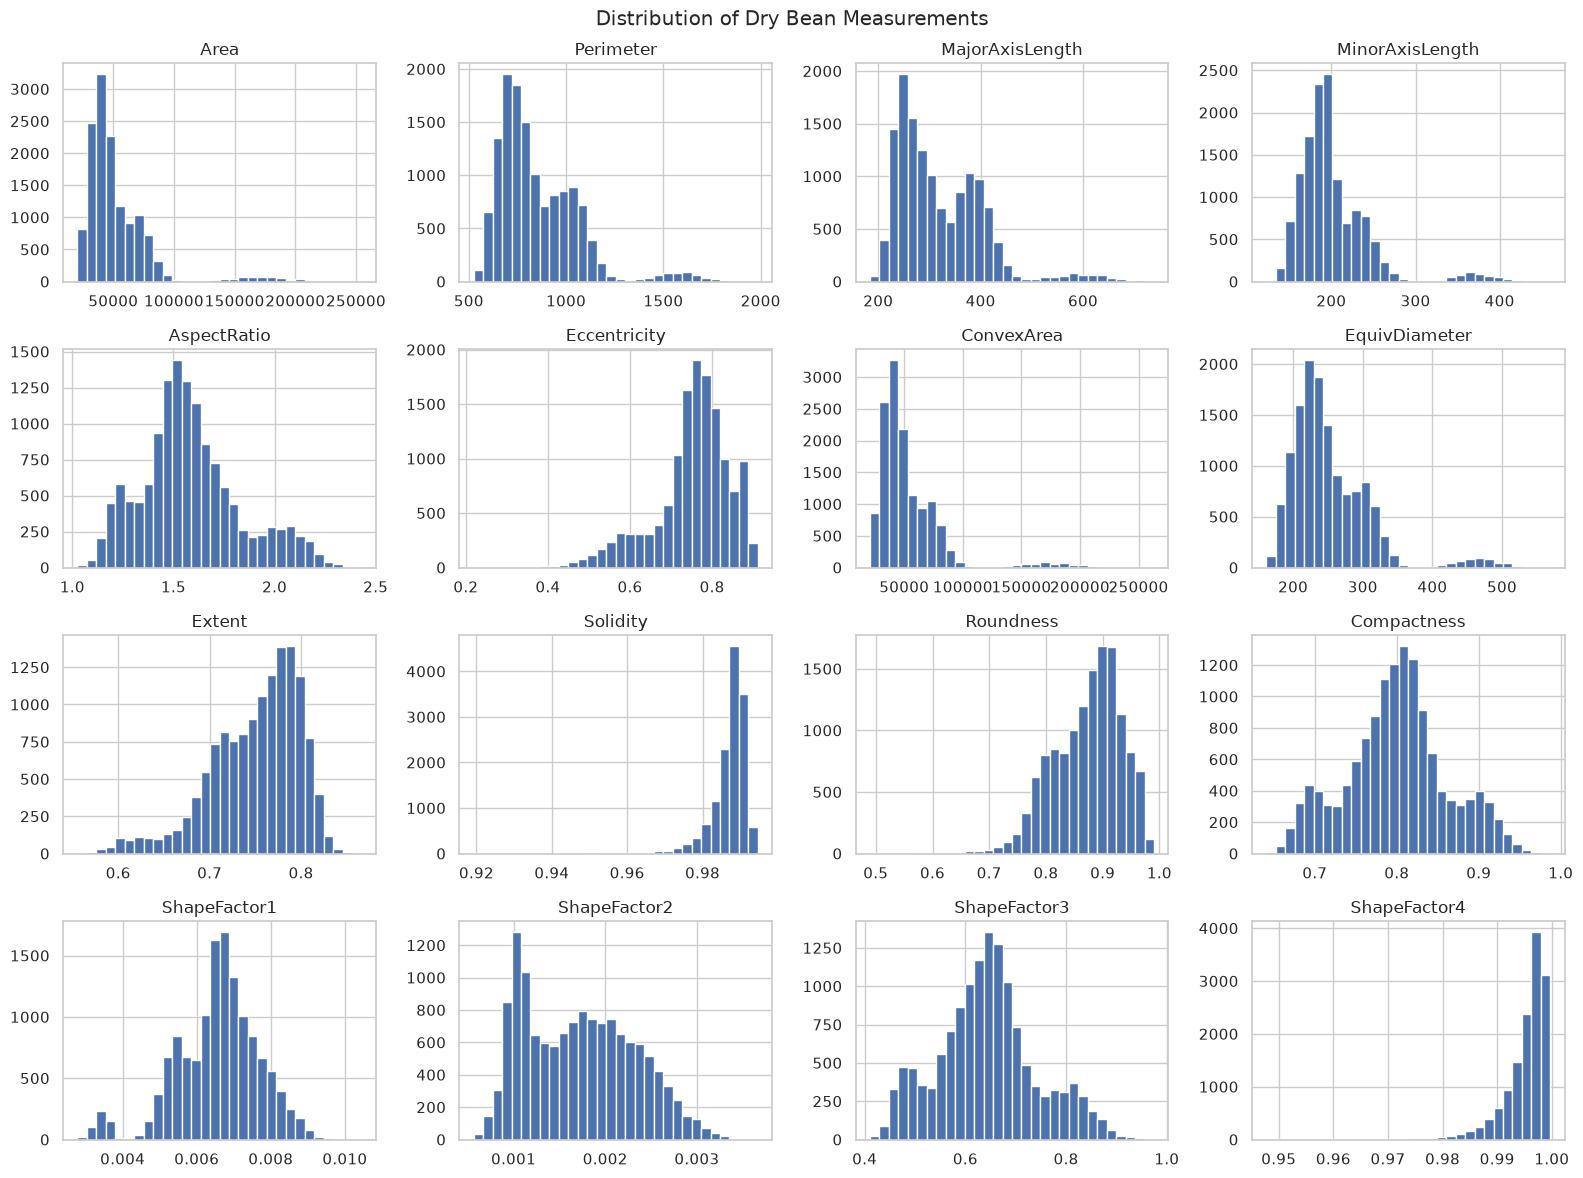

In [5]:
X.hist(figsize=(16, 12), bins=30)

plt.suptitle("Distribution of Dry Bean Measurements")

plt.tight_layout()

plt.show()

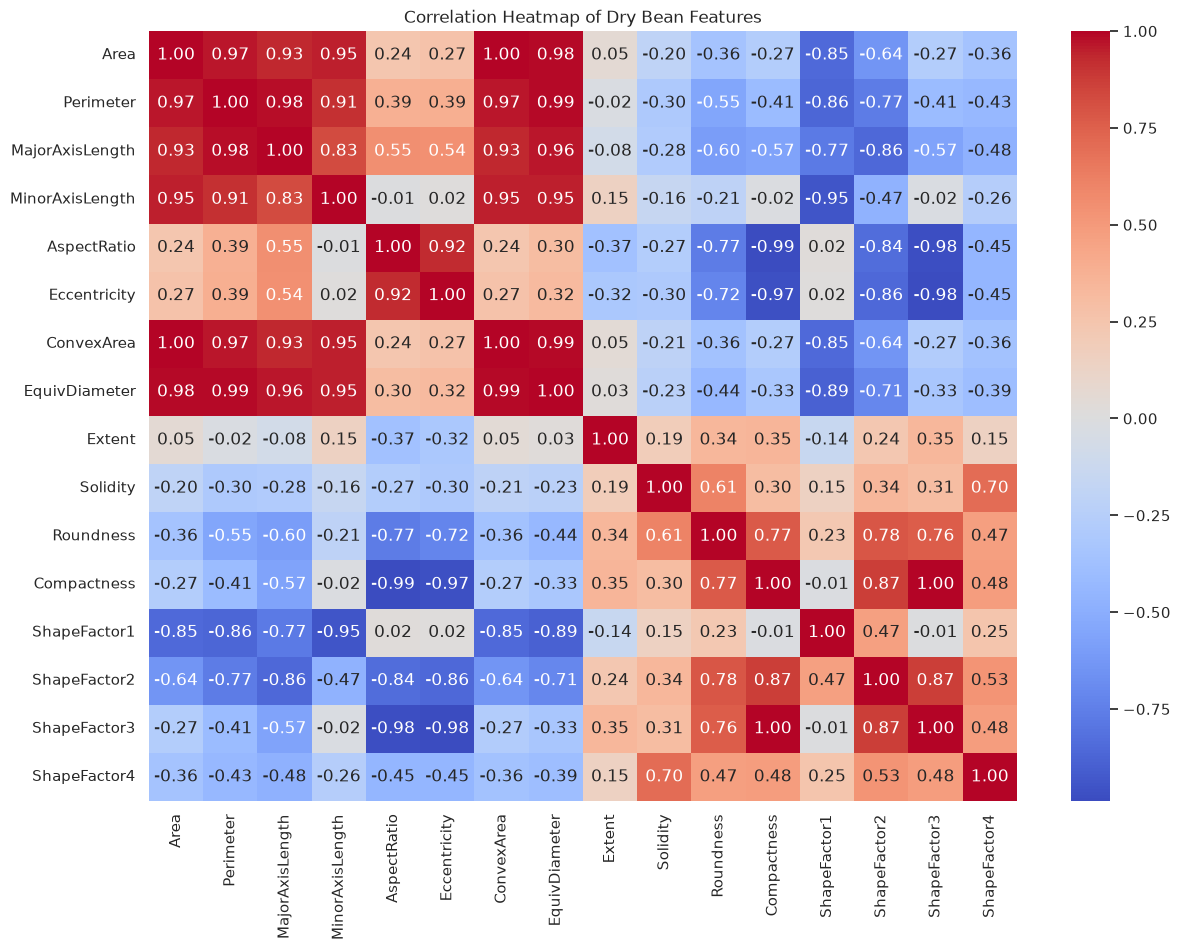

In [6]:
plt.figure(figsize=(14, 10))

sns.heatmap(
    X.corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
)

plt.title("Correlation Heatmap of Dry Bean Features")

plt.show()

## Prepare Data for Machine Learning

### Split training data and test data

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y, 
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 10888
Testing samples: 2723


## Build Machine Learning Models

### Logistic regression

In [9]:
logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=2000, random_state=42))
])

### Train the model

In [10]:
start_time = time.perf_counter()

logistic_model.fit(X_train, y_train)

logistic_training_time = time.perf_counter() - start_time

### Evaluate the model

In [11]:
logistic_train_pred = logistic_model.predict(X_train)

logistic_test_pred = logistic_model.predict(X_test)

logistic_train_accuracy = accuracy_score(y_train, logistic_train_pred)

logistic_test_accuracy = accuracy_score(y_test, logistic_test_pred)

print("Training Accuracy:", logistic_train_accuracy)
print("Testing Accuracy:", logistic_test_accuracy)
print("Training Time:", logistic_training_time)

Training Accuracy: 0.9259735488611315
Testing Accuracy: 0.9206757253029747
Training Time: 2.141055181000411


## Decision Tree

In [12]:
tree_model = DecisionTreeClassifier(random_state=42, max_depth=10)

### Train the model

In [13]:
start_time = time.perf_counter()

tree_model.fit(X_train, y_train)

tree_training_time = time.perf_counter() - start_time

### Evaluate the model

In [14]:
tree_train_pred = tree_model.predict(X_train)

tree_test_pred = tree_model.predict(X_test)

tree_train_accuracy = accuracy_score(y_train, tree_train_pred)

tree_test_accuracy = accuracy_score(y_test, tree_test_pred)

print("Training Accuracy:", tree_train_accuracy)
print("Testing Accuracy:", tree_test_accuracy)
print("Training Time:", tree_training_time)

Training Accuracy: 0.9634459955914768
Testing Accuracy: 0.9056188027910393
Training Time: 0.9363187180006207


### Visualize the tree

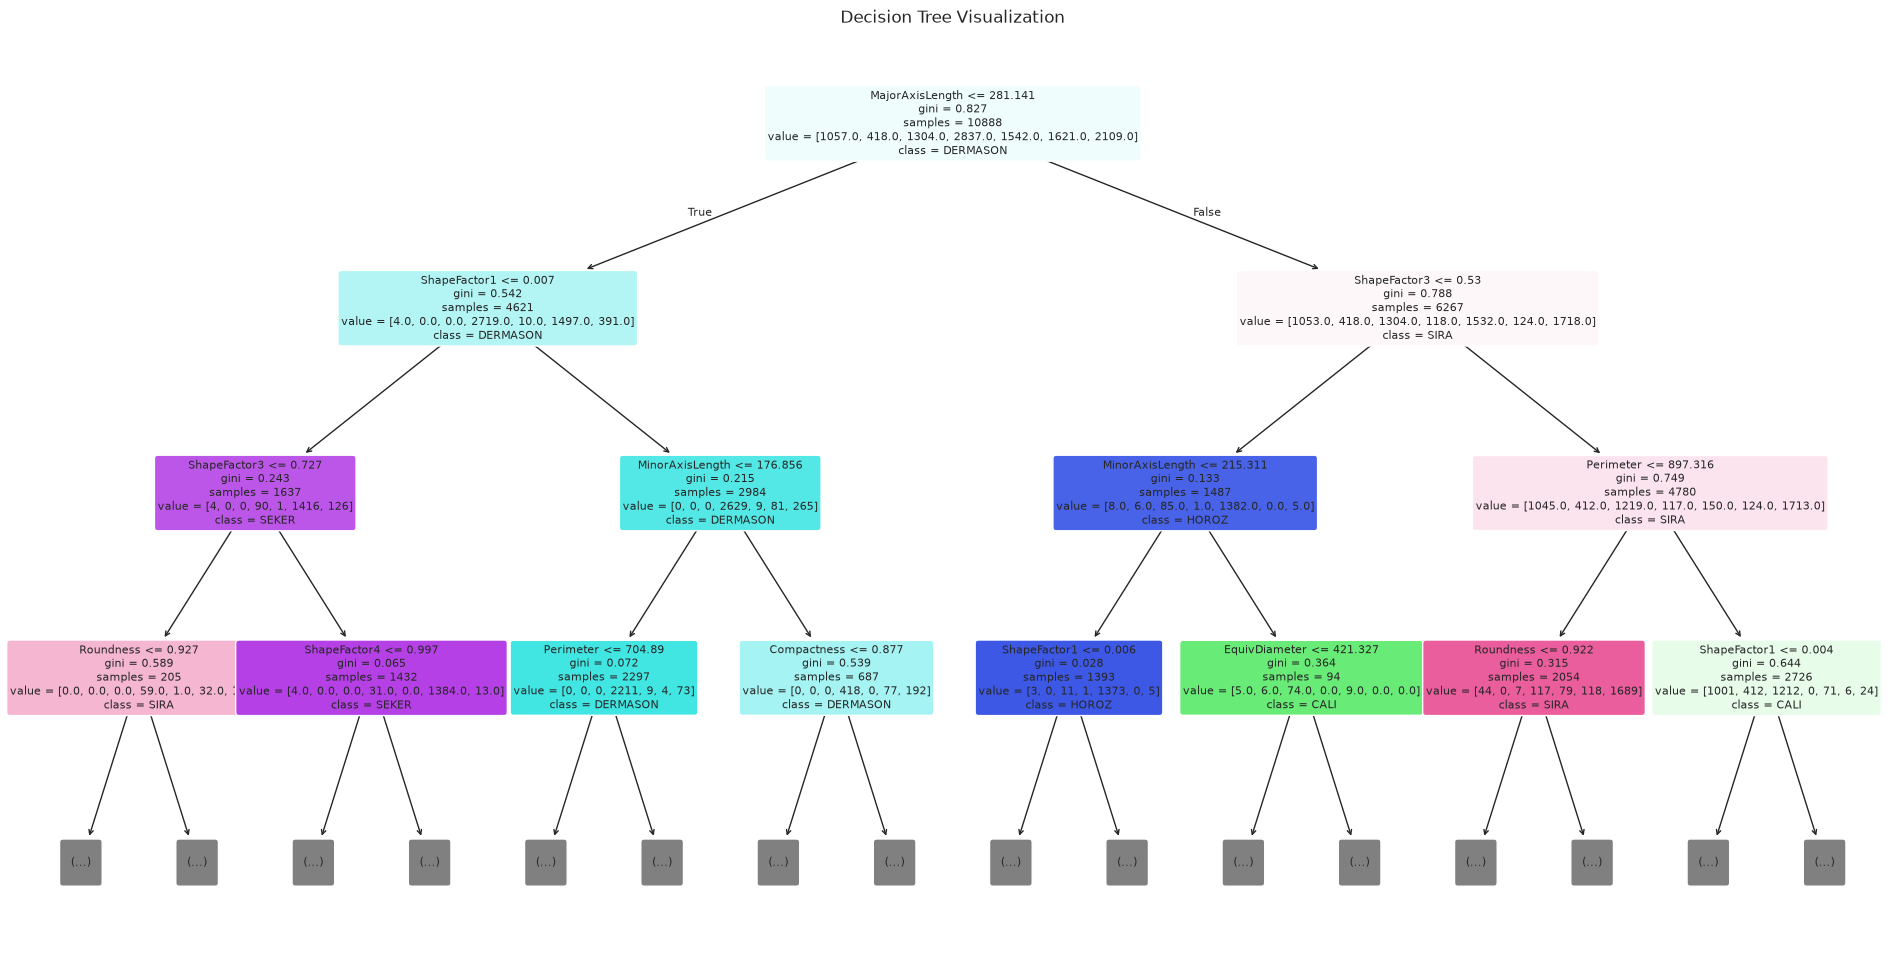

In [15]:
from sklearn.tree import plot_tree

plt.figure(figsize=(24, 12))

plot_tree(
    tree_model,
    feature_names=X.columns,
    class_names=tree_model.classes_,
    filled=True,
    rounded=True,
    fontsize=8,
    max_depth=3
)

plt.title("Decision Tree Visualization")

plt.show()

## Random Forest Model

In [16]:
random_forest_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    random_state=42,
    n_jobs=-1
)

### Train the model

In [17]:
start_time = time.perf_counter()

random_forest_model.fit(X_train, y_train)

random_forest_training_time = time.perf_counter() - start_time

### Evaluate the model

In [18]:
rf_train_pred = random_forest_model.predict(X_train)

rf_test_pred = random_forest_model.predict(X_test)

rf_train_accuracy = accuracy_score(y_train, rf_train_pred)

rf_test_accuracy = accuracy_score(y_test, rf_test_pred)

print("Training Accuracy:", rf_train_accuracy)
print("Testing Accuracy:", rf_test_accuracy)
print("Training Time:", random_forest_training_time)

Training Accuracy: 0.9960506980161646
Testing Accuracy: 0.9188395152405435
Training Time: 2.9692389640003967


### Examine feature importance

In [20]:
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": random_forest_model.feature_importances_
})

feature_importance = feature_importance.sort_values(by="Importance", ascending=False)

display(feature_importance)

,Feature,Importance
14,ShapeFactor3,0.106208
1,Perimeter,0.105823
11,Compactness,0.085549
12,ShapeFactor1,0.085372
3,MinorAxisLength,0.080489
6,ConvexArea,0.072175
2,MajorAxisLength,0.070596
4,AspectRatio,0.065543
5,Eccentricity,0.064083
10,Roundness,0.059348


### Visualize the results

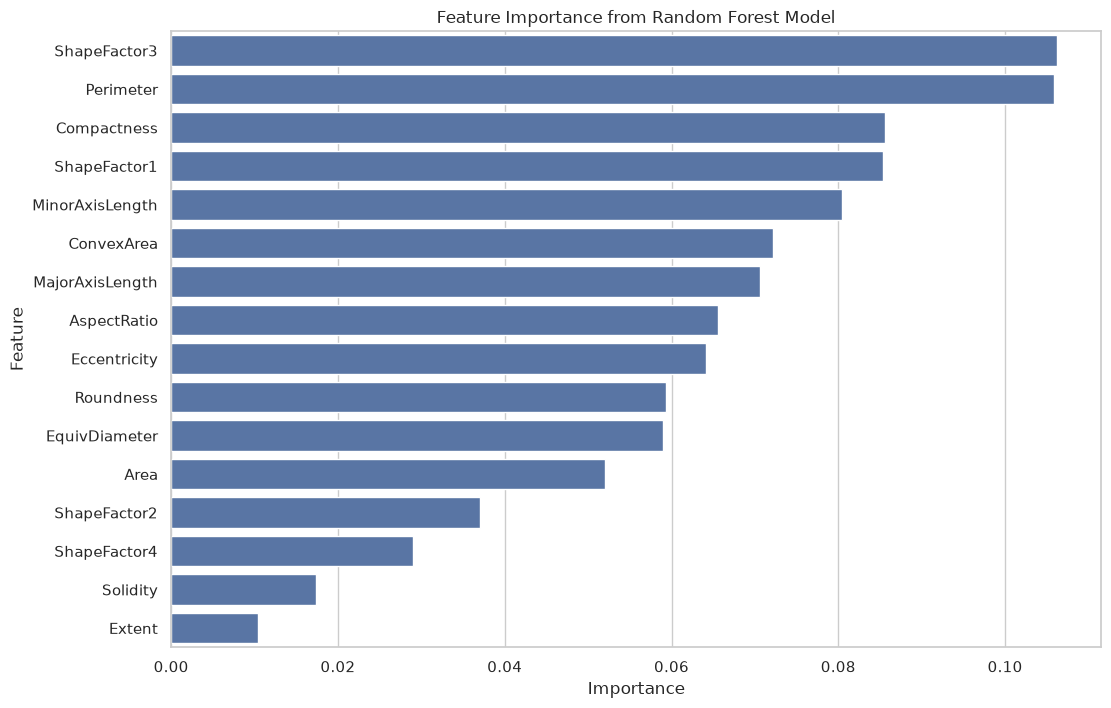

In [24]:
plt.figure(figsize=(12, 8))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Feature Importance from Random Forest Model")

plt.show()

## Hist Boosting Model

In [25]:
boosting_model = HistGradientBoostingClassifier(
    max_iter=150,
    learning_rate=0.1,
    max_leaf_nodes=31,
    random_state=42
)

### Train the model

In [26]:
start_time = time.perf_counter()

boosting_model.fit(X_train, y_train)

boosting_training_time = time.perf_counter() - start_time

### Evaluate the model

In [27]:
boost_train_pred = boosting_model.predict(X_train)

boost_test_pred = boosting_model.predict(X_test)

boost_train_accuracy = accuracy_score(y_train, boost_train_pred)

boost_test_accuracy = accuracy_score(y_test, boost_test_pred)

print("Training Accuracy:", boost_train_accuracy)
print("Testing Accuracy:", boost_test_accuracy)
print("Training Time:", boosting_training_time)

Training Accuracy: 0.9868662747979426
Testing Accuracy: 0.9221446933529196
Training Time: 3.9970652790016175


## Model Comparison

In [28]:
models = {
    "logistic regression": logistic_model,
    "decision tree": tree_model,
    "random forest": random_forest_model,
    "hist gradient boosting": boosting_model
}

### Cross-validation strategy

In [29]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

### Cross validation

In [30]:
cv_results = []

for name, model in models.items():
    print(f"Evaluating {name}...")

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv = cv,
        scoring = {
            "accuracy": "accuracy",
            "f1_macro": "f1_macro"
        },
        return_train_score=True,
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "Train Accuracy": scores["train_accuracy"].mean(),
        "Validation Accuracy": scores["test_accuracy"].mean(),
        "Validation Accuracy Std": scores["test_accuracy"].std(),
        "Validation F1 Macro": scores["test_f1_macro"].mean(),
        "Average Training Time": scores["fit_time"].mean()
    })

cv_df = pd.DataFrame(cv_results)

display(cv_df)

Evaluating logistic regression...
Evaluating decision tree...
Evaluating random forest...
Evaluating hist gradient boosting...


,Model,Train Accuracy,Validation Accuracy,Validation Accuracy Std,Validation F1 Macro,Average Training Time
0,logistic regression,0.925974,0.923861,0.004095,0.935284,1.012653
1,decision tree,0.967694,0.906502,0.003352,0.919277,0.659304
2,random forest,0.996326,0.925146,0.005648,0.935726,9.804915
3,hist gradient boosting,1.000000,0.928360,0.007107,0.940483,19.577481


### Model comparsion table

In [32]:
comparison_results = []

for name, model in models.items():
    start_time = time.perf_counter()

    model.fit(X_train, y_train)

    training_time = time.perf_counter() - start_time

    train_predictions = model.predict(X_train)

    start_time = time.perf_counter()

    test_predictions = model.predict(X_test)

    prediction_time = time.perf_counter() - start_time

    comparison_results.append({

        "Model": name,

        "Training Accuracy": accuracy_score(
            y_train,
            train_predictions
        ),

        "Testing Accuracy": accuracy_score(
            y_test,
            test_predictions
        ),

        "Testing Macro F1": f1_score(
            y_test,
            test_predictions,
            average="macro"
        ),

        "Training Time (seconds)": training_time,

        "Prediction Time (seconds)": prediction_time,

        "Prediction Time Per Bean (ms)": (
            prediction_time / len(X_test)
        ) * 1000

    })

comparison_df = pd.DataFrame(comparison_results)

display(
    comparison_df.sort_values(
        by="Testing Accuracy",
        ascending=False
    )
)

,Model,Training Accuracy,Testing Accuracy,Testing Macro F1,Training Time (seconds),Prediction Time (seconds),Prediction Time Per Bean (ms)
3,hist gradient boosting,0.986866,0.922145,0.934353,3.571425,0.069100,0.025376
0,logistic regression,0.925974,0.920676,0.932897,2.163671,0.012454,0.004573
2,random forest,0.996051,0.918840,0.931317,2.636412,0.124273,0.045638
1,decision tree,0.963446,0.905619,0.920306,0.660482,0.004327,0.001589


## Examine classification performance

In [33]:
rf_pred = random_forest_model.predict(X_test)

print(classification_report(y_test, rf_pred))

              precision    recall  f1-score   support

    BARBUNYA       0.94      0.89      0.91       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.94      0.94      0.94       326
    DERMASON       0.91      0.92      0.91       709
       HOROZ       0.96      0.95      0.96       386
       SEKER       0.94      0.96      0.95       406
        SIRA       0.85      0.85      0.85       527

    accuracy                           0.92      2723
   macro avg       0.93      0.93      0.93      2723
weighted avg       0.92      0.92      0.92      2723



### Create a confusion matrix

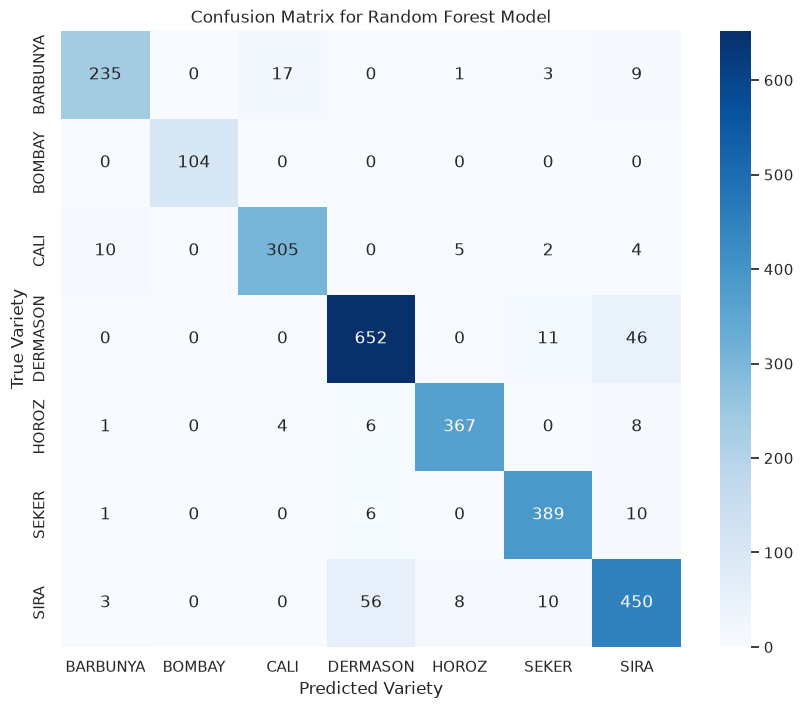

In [35]:
cm = confusion_matrix(y_test, rf_pred, labels=random_forest_model.classes_)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=random_forest_model.classes_,
    yticklabels=random_forest_model.classes_
)

plt.xlabel("Predicted Variety")

plt.ylabel("True Variety")

plt.title("Confusion Matrix for Random Forest Model")

plt.show()

## Explain the models decisions

In [36]:
from sklearn.inspection import permutation_importance

permutation_results = permutation_importance(
    random_forest_model,
    X_test,
    y_test,
    n_repeats=10,
    random_state=42,
    n_jobs=-1,
    scoring="f1_macro"
)

permutation_df = pd.DataFrame({
    "Feature": X.columns,
    "Importance": permutation_results.importances_mean,
    "Standard Deviation": permutation_results.importances_std
})

permutation_df = permutation_df.sort_values(by="Importance", ascending=False)

display(permutation_df)

,Feature,Importance,Standard Deviation
10,Roundness,0.074738,0.003309
15,ShapeFactor4,0.037375,0.002968
1,Perimeter,0.007376,0.001383
11,Compactness,0.004065,0.001901
9,Solidity,0.003808,0.001701
14,ShapeFactor3,0.002652,0.001428
2,MajorAxisLength,0.002020,0.001183
13,ShapeFactor2,0.001667,0.001428
8,Extent,0.000927,0.001302
6,ConvexArea,0.000918,0.000765


### Visualize permutation feature importance

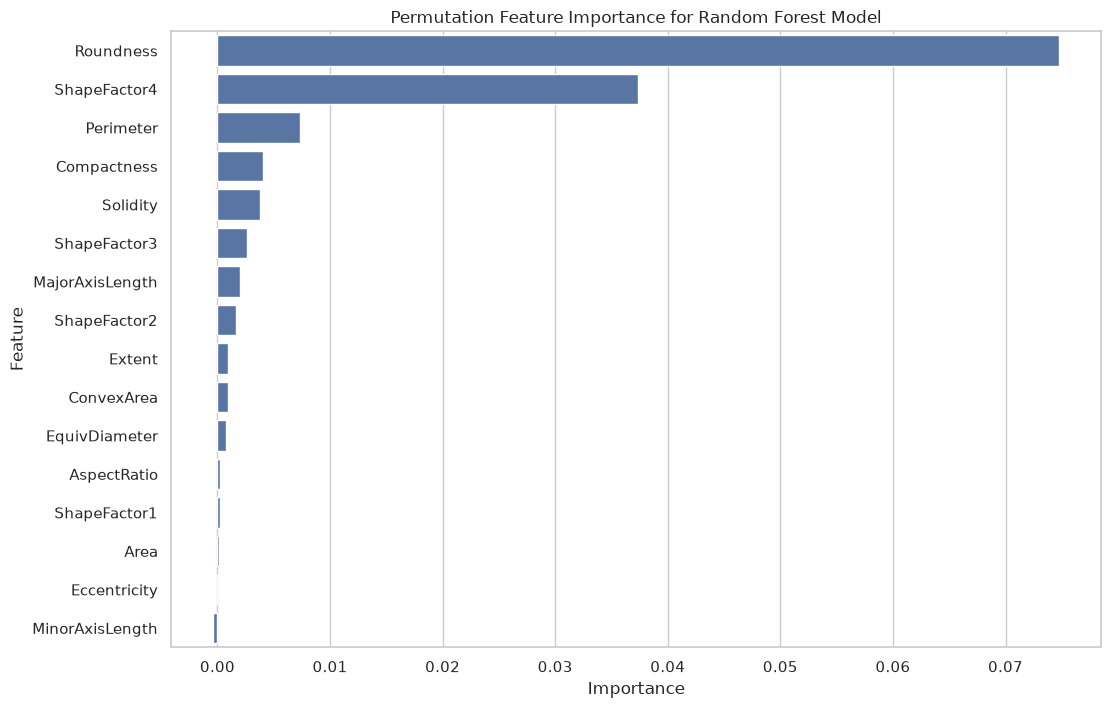

In [38]:
plt.figure(figsize=(12, 8))

sns.barplot(
    data=permutation_df,
    x="Importance",
    y="Feature"
)

plt.title("Permutation Feature Importance for Random Forest Model")

plt.show()

## Preform unsupervised learning using Clustering

In [39]:
clustering_scaler = StandardScaler()

X_scaled = clustering_scaler.fit_transform(X)

### Find the number of clusters

In [40]:
inertia_values = []

cluster_numbers = range(2, 11)

for k in cluster_numbers:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)

    inertia_values.append(kmeans.inertia_)

### Visualize

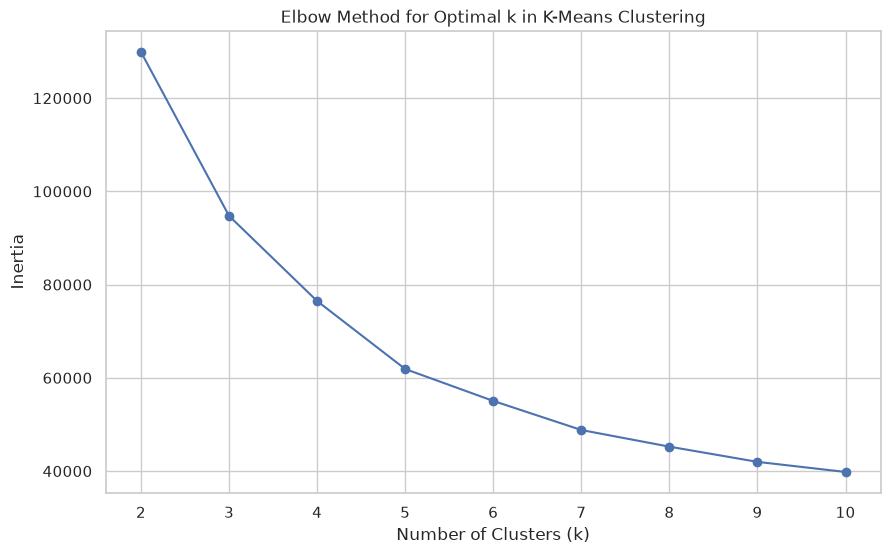

In [41]:
plt.figure(figsize=(10, 6))

plt.plot(cluster_numbers, inertia_values, marker='o')

plt.xlabel("Number of Clusters (k)")

plt.ylabel("Inertia")

plt.title("Elbow Method for Optimal k in K-Means Clustering")

plt.show()

### Evaluate cluster quality using silhouette scores

In [42]:
silhouette_values = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    cluster_labels = kmeans.fit_predict(X_scaled)

    silhouette_avg = silhouette_score(X_scaled, cluster_labels)

    silhouette_values.append(silhouette_avg)

### Visualize

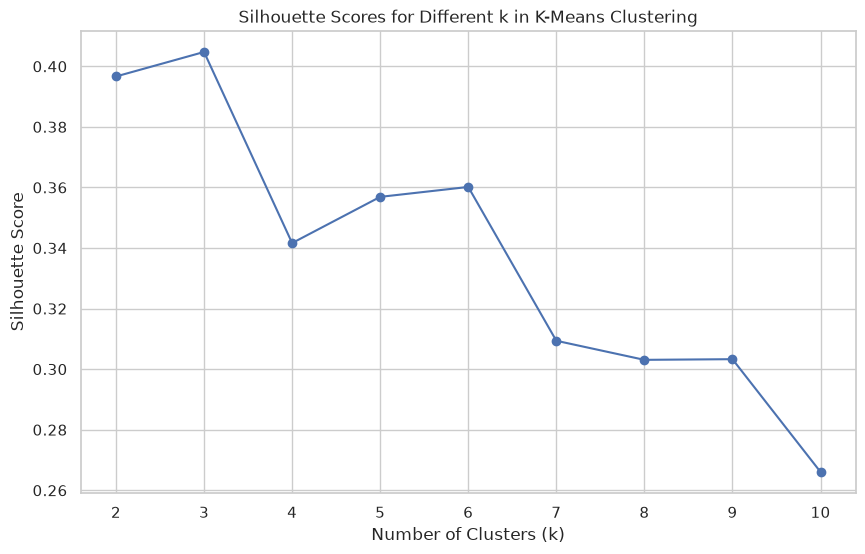

In [43]:
plt.figure (figsize=(10, 6))

plt.plot(range(2, 11), silhouette_values, marker='o')

plt.xlabel("Number of Clusters (k)")

plt.ylabel("Silhouette Score")

plt.title("Silhouette Scores for Different k in K-Means Clustering")

plt.show()

### Perform the final clustering

In [44]:
final_kmeans = KMeans(
    n_clusters=7,
    random_state=42,
    n_init=10
)

cluster_labels = final_kmeans.fit_predict(X_scaled)

In [45]:
clustering_results = X.copy()

clustering_results["Cluster"] = cluster_labels

display(clustering_results.head())

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRatio,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,Roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Cluster
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,2
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272751,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,2
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,2
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,2
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,2


### Comapre clusters with the hidden labels

In [46]:
cluster_comparision = pd.crosstab(
    cluster_labels,
    y,
    rownames=["Cluster"],
    colnames=["True Variety"]
)

display(cluster_comparision)

True Variety,BARBUNYA,BOMBAY,CALI,DERMASON,HOROZ,SEKER,SIRA
Cluster,,,,,,,
0,1142,1,1303,0,29,0,5
1,114,0,25,499,49,98,2326
2,18,0,2,115,0,1874,24
3,8,0,30,7,1661,0,63
4,0,0,0,2912,2,52,191
5,0,520,0,0,0,0,0
6,40,1,270,13,187,3,27


In [47]:
ari = adjusted_rand_score(y, cluster_labels)

print("Adjusted Rand Index (ARI):", ari)

Adjusted Rand Index (ARI): 0.6686956744848731


In [48]:
nmi = normalized_mutual_info_score(y, cluster_labels)

print("Normalized Mutual Information (NMI):", nmi)

Normalized Mutual Information (NMI): 0.7137637558816042


In [49]:
pca = PCA(n_components=2, random_state=42)

X_pca = pca.fit_transform(X_scaled)

### Visualize the clusters

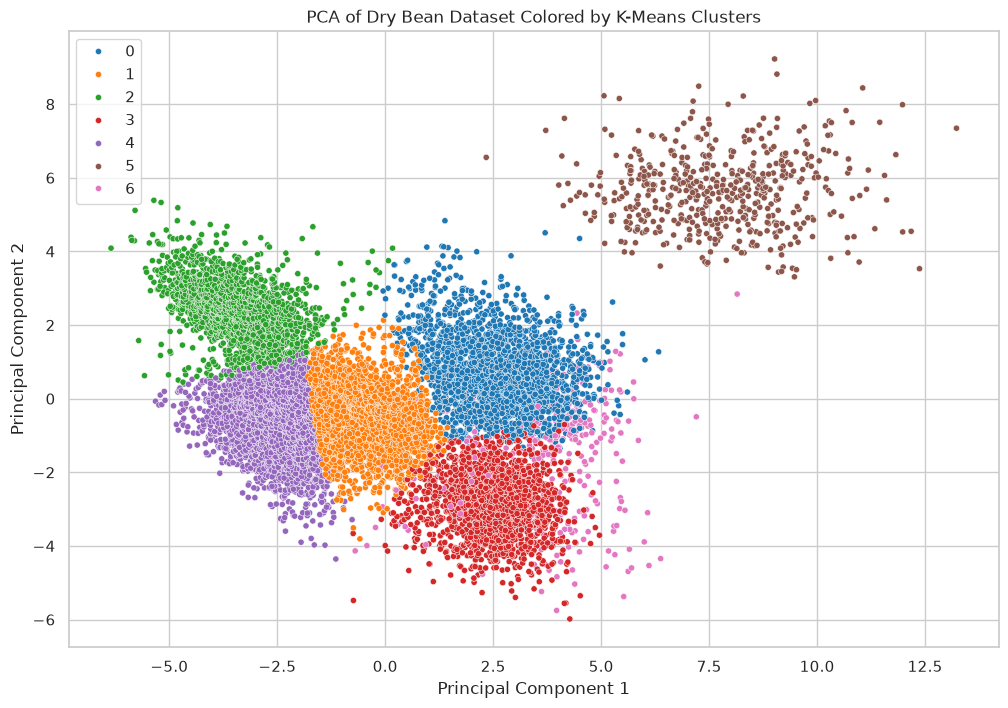

In [50]:
plt.figure(figsize=(12, 8))

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=cluster_labels,
    palette="tab10",
    s=20
)

plt.xlabel("Principal Component 1")

plt.ylabel("Principal Component 2")

plt.title("PCA of Dry Bean Dataset Colored by K-Means Clusters")

plt.show()

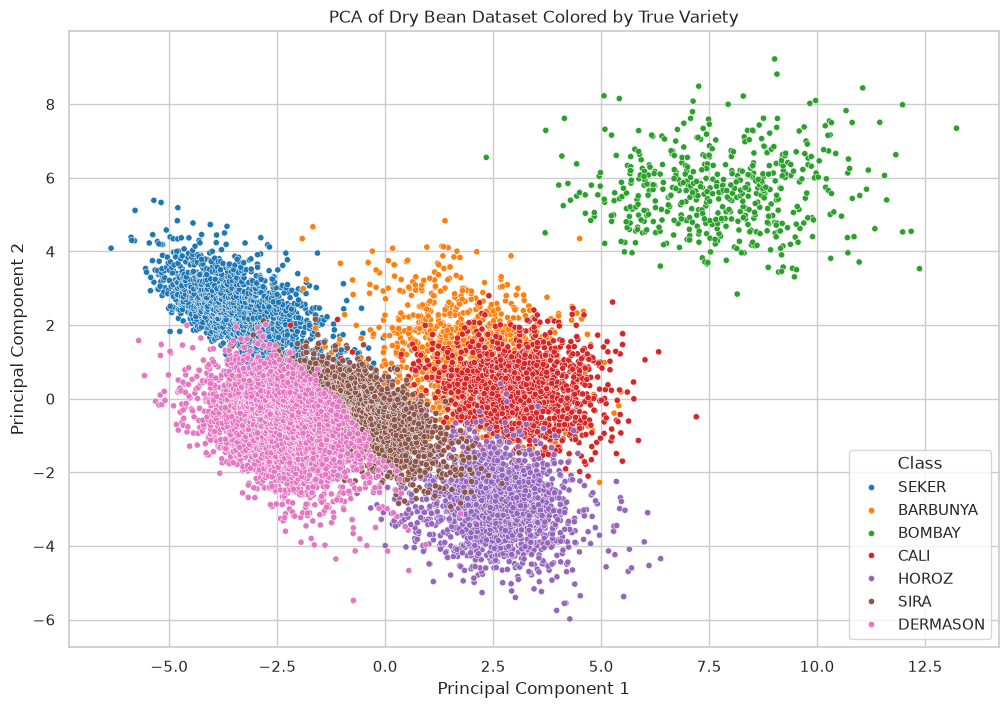

In [51]:
plt.figure(figsize=(12, 8))

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=y,
    palette="tab10",
    s=20
)

plt.xlabel("Principal Component 1")

plt.ylabel("Principal Component 2")

plt.title("PCA of Dry Bean Dataset Colored by True Variety")

plt.show()